In [2]:
# Part 1: Prepare Hourly Time-Series Data

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 5)

# 1. Load raw orders dataset
data_path = '../data/orders.csv'
if not os.path.exists(data_path):
    data_path = 'data/orders.csv'

orders_df = pd.read_csv(data_path)
print("Available columns in orders.csv:", orders_df.columns.tolist())

# 2. Dynamically identify datetime column
possible_date_cols = [
    col for col in orders_df.columns 
    if any(keyword in col.lower() for keyword in ['time', 'date', 'created', 'at'])
]

if not possible_date_cols:
    raise ValueError(f"Could not find a date/time column. Available columns are: {orders_df.columns.tolist()}")

chosen_date_col = possible_date_cols[0]
print(f"Using '{chosen_date_col}' as the timestamp column.")

# Convert to datetime series
orders_df['timestamp'] = pd.to_datetime(orders_df[chosen_date_col], errors='coerce')
orders_df = orders_df.dropna(subset=['timestamp'])

# 3. Aggregate transactions into hourly order volume
hourly_series = orders_df.set_index('timestamp').resample('h').size()
hourly_demand = hourly_series.asfreq('h', fill_value=0).reset_index()
hourly_demand.columns = ['timestamp', 'order_count']

# 4. Display sample aggregated records
print("\n=== Hourly Order Demand Preview ===")
display(hourly_demand.head(10))

# 5. Export Deliverable: Hourly demand dataset
export_path = '../data/hourly_order_demand.csv'
if not os.path.exists('../data'):
    export_path = 'data/hourly_order_demand.csv'
    
hourly_demand.to_csv(export_path, index=False)
print(f"\nSaved hourly dataset to: {export_path}")
print(f"Total hourly timesteps: {len(hourly_demand)}")

Available columns in orders.csv: ['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'num_items', 'distance_km', 'weather', 'traffic', 'prep_time_min', 'status', 'delivery_time_min', 'tip_amount']
Using 'order_timestamp' as the timestamp column.

=== Hourly Order Demand Preview ===


,timestamp,order_count
0,2025-10-23 09:00:00,3
1,2025-10-23 10:00:00,2
2,2025-10-23 11:00:00,1
3,2025-10-23 12:00:00,1
4,2025-10-23 13:00:00,2
5,2025-10-23 14:00:00,3
6,2025-10-23 15:00:00,1
7,2025-10-23 16:00:00,0
8,2025-10-23 17:00:00,1
9,2025-10-23 18:00:00,1



Saved hourly dataset to: ../data/hourly_order_demand.csv
Total hourly timesteps: 8765


/tmp/ipykernel_10106/4075472848.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_eda['day_idx'] = df_eda['timestamp'].dt.dayofweek
/tmp/ipykernel_10106/4075472848.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=daily_profile, x='day_of_week', y='order_count', palette='Blues_d', ax=axes[0, 1])


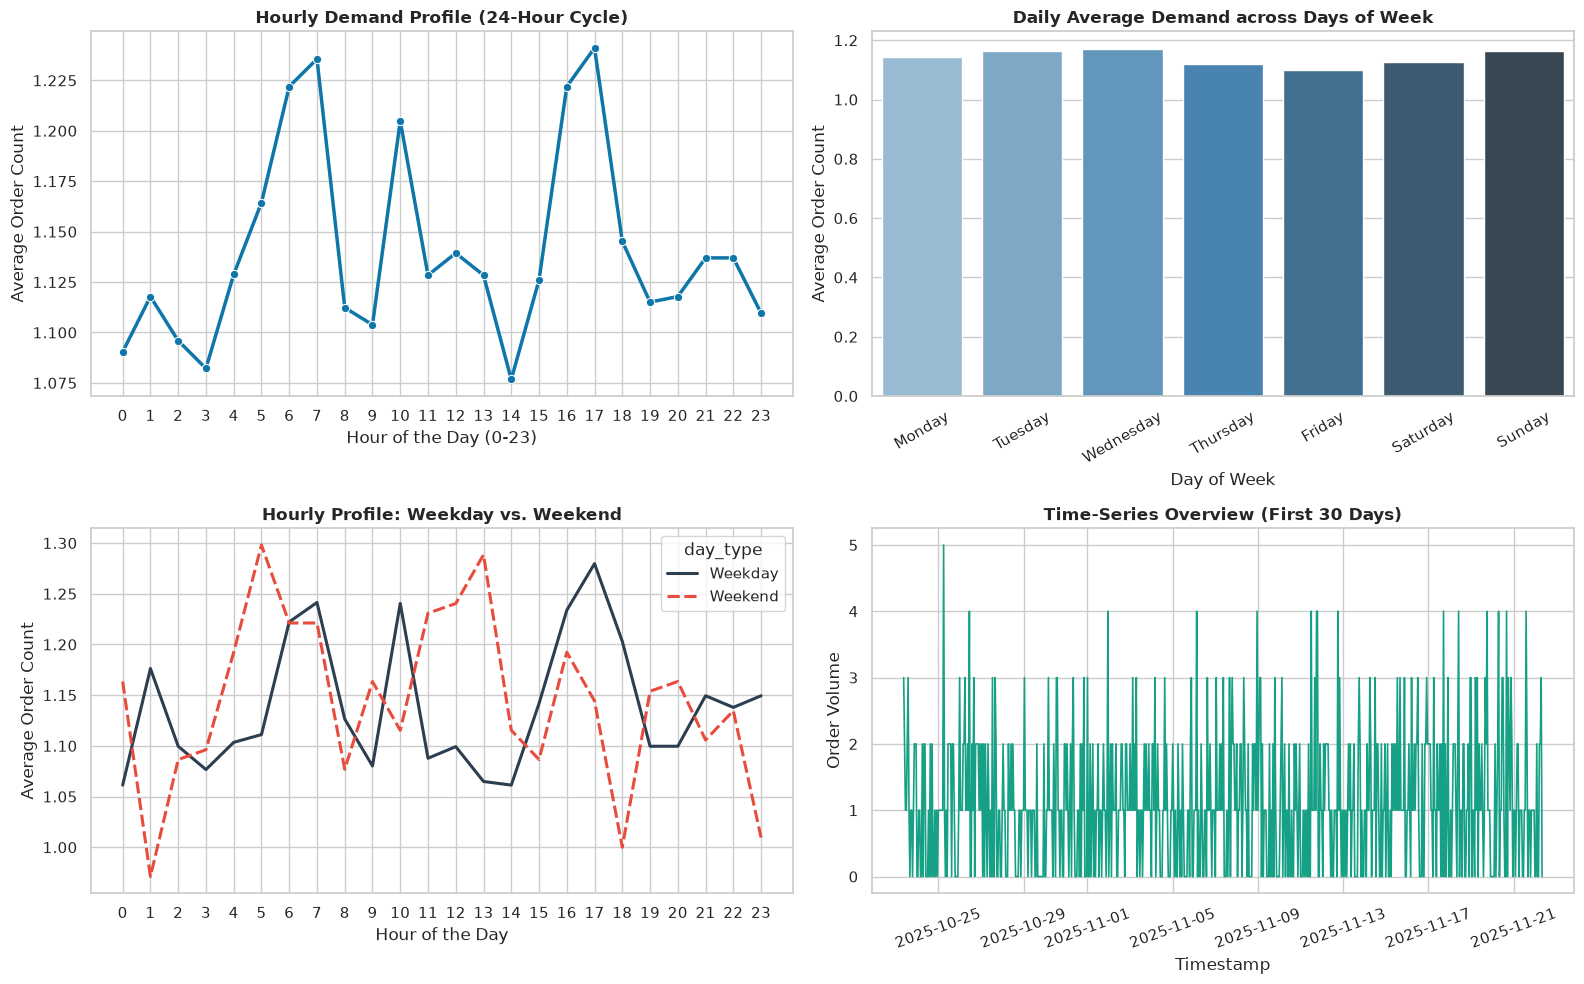

=== Exploratory Findings: Demand Signatures ===
- Overall Peak Hour: 17:00 (Avg 1.2 orders)
- Lunch Rush Window: Peak at 12:00 (Avg 1.1 orders)
- Dinner Surge Window: Peak at 18:00 (Avg 1.1 orders)
- Highest Demand Day: Wednesday


In [3]:

df_eda = hourly_demand.copy()
df_eda['timestamp'] = pd.to_datetime(df_eda['timestamp'])
df_eda['hour'] = df_eda['timestamp'].dt.hour
df_eda['day_of_week'] = df_eda['timestamp'].dt.day_name()
df_eda['day_idx'] = df_eda['timestamp'].dt.dayofweek
df_eda['is_weekend'] = df_eda['day_idx'] >= 5
df_eda['day_type'] = np.where(df_eda['is_weekend'], 'Weekend', 'Weekday')

# Day order for plotting
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# 2. Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Subplot A: Hourly Demand Trend (24-Hour Cycle)
hourly_profile = df_eda.groupby('hour')['order_count'].mean().reset_index()
sns.lineplot(data=hourly_profile, x='hour', y='order_count', marker='o', color='#0e76a8', lw=2.5, ax=axes[0, 0])
axes[0, 0].set_title('Hourly Demand Profile (24-Hour Cycle)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Hour of the Day (0-23)')
axes[0, 0].set_ylabel('Average Order Count')
axes[0, 0].set_xticks(range(0, 24))

# Subplot B: Daily Pattern Across Days of the Week
daily_profile = df_eda.groupby('day_of_week')['order_count'].mean().reindex(days_order).reset_index()
sns.barplot(data=daily_profile, x='day_of_week', y='order_count', palette='Blues_d', ax=axes[0, 1])
axes[0, 1].set_title('Daily Average Demand across Days of Week', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Day of Week')
axes[0, 1].set_ylabel('Average Order Count')
axes[0, 1].tick_params(axis='x', rotation=30)

# Subplot C: Weekday vs. Weekend Hourly Comparison
weekday_weekend = df_eda.groupby(['hour', 'day_type'])['order_count'].mean().reset_index()
sns.lineplot(data=weekday_weekend, x='hour', y='order_count', hue='day_type', style='day_type',
             palette={'Weekday': '#2c3e50', 'Weekend': '#e74c3c'}, lw=2.2, ax=axes[1, 0])
axes[1, 0].set_title('Hourly Profile: Weekday vs. Weekend', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Hour of the Day')
axes[1, 0].set_ylabel('Average Order Count')
axes[1, 0].set_xticks(range(0, 24))

# Subplot D: Macro Timeline Trend
sample_length = min(len(df_eda), 24 * 30)  # Plot 30 days for clarity
sns.lineplot(data=df_eda.iloc[:sample_length], x='timestamp', y='order_count', color='#16a085', lw=1.2, ax=axes[1, 1])
axes[1, 1].set_title(f'Time-Series Overview (First {sample_length//24} Days)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Timestamp')
axes[1, 1].set_ylabel('Order Volume')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# 3. Peak Ordering Diagnostics
peak_hours = hourly_profile.sort_values(by='order_count', ascending=False).head(3)
lunch_peak = hourly_profile[(hourly_profile['hour'] >= 11) & (hourly_profile['hour'] <= 15)].sort_values(by='order_count', ascending=False).iloc[0]
dinner_peak = hourly_profile[(hourly_profile['hour'] >= 18) & (hourly_profile['hour'] <= 22)].sort_values(by='order_count', ascending=False).iloc[0]

print("=== Exploratory Findings: Demand Signatures ===")
print(f"- Overall Peak Hour: {int(peak_hours.iloc[0]['hour'])}:00 (Avg {peak_hours.iloc[0]['order_count']:.1f} orders)")
print(f"- Lunch Rush Window: Peak at {int(lunch_peak['hour'])}:00 (Avg {lunch_peak['order_count']:.1f} orders)")
print(f"- Dinner Surge Window: Peak at {int(dinner_peak['hour'])}:00 (Avg {dinner_peak['order_count']:.1f} orders)")
print(f"- Highest Demand Day: {daily_profile.sort_values(by='order_count', ascending=False).iloc[0]['day_of_week']}")

ModuleNotFoundError: No module named 'statsmodels'

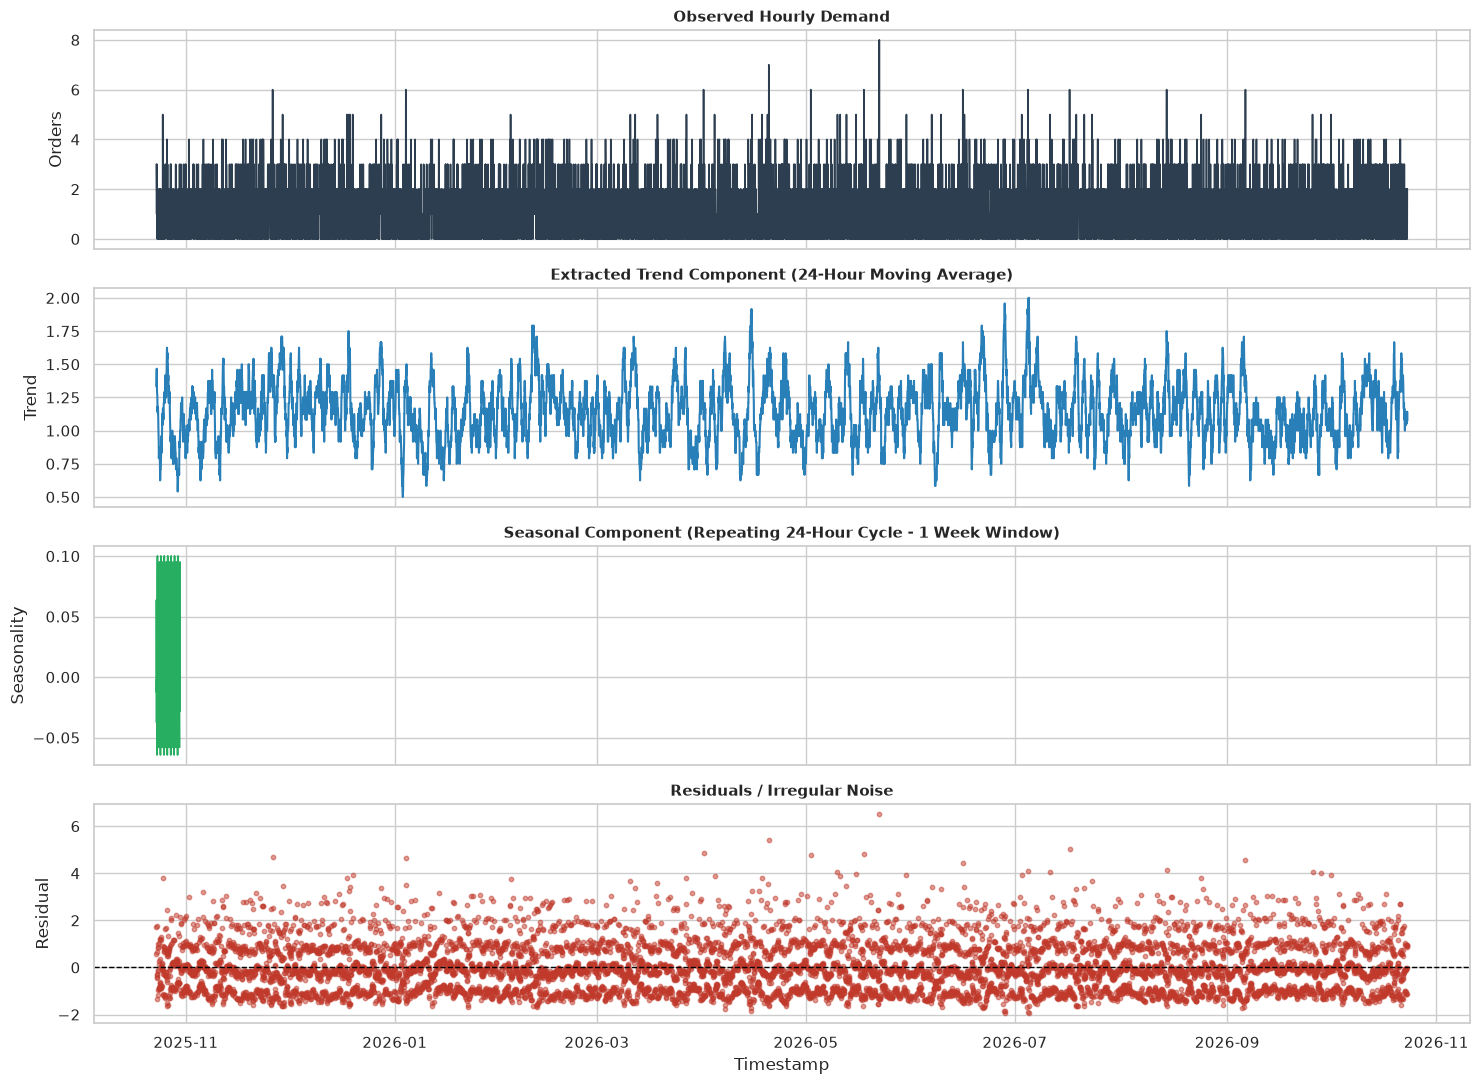

=== Decomposition Diagnostic Summary ===
- Total Time Steps Analyzed: 8765
- Seasonal Periodicity: 24 hours (Daily cycle)
- Residual Mean: 0.000 (Near zero indicates unbiased decomposition)
- Residual Standard Deviation: 1.036


In [8]:
# Part 3: Time-Series Decomposition (Pure Pandas / NumPy Implementation)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Prepare continuous indexed time series
ts_series = hourly_demand.set_index('timestamp')['order_count'].asfreq('h', fill_value=0)

# 2. Additive Decomposition with 24-hour daily periodicity
period = 24

# A. Trend Component: 24-hour centered moving average
trend = ts_series.rolling(window=period, center=True, min_periods=period // 2).mean()

# B. Detrend the series to isolate periodic behavior
detrended = ts_series - trend

# C. Seasonal Component: Mean profile for each hour of the day across all days
seasonal_by_hour = detrended.groupby(detrended.index.hour).transform('mean')

# D. Residual / Noise Component: What remains after removing trend and seasonality
residuals = ts_series - trend - seasonal_by_hour

# 3. Visualization: Observed, Trend, Seasonality, and Residuals
fig, axes = plt.subplots(4, 1, figsize=(15, 11), sharex=True)

# Observed
axes[0].plot(ts_series.index, ts_series.values, color='#2c3e50', lw=1.2)
axes[0].set_title('Observed Hourly Demand', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Orders')

# Trend
axes[1].plot(trend.index, trend.values, color='#2980b9', lw=1.5)
axes[1].set_title('Extracted Trend Component (24-Hour Moving Average)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Trend')

# Seasonality (1-week preview for visual clarity)
sample_window = 24 * 7
axes[2].plot(seasonal_by_hour.index[:sample_window], seasonal_by_hour.values[:sample_window], color='#27ae60', lw=1.2)
axes[2].set_title('Seasonal Component (Repeating 24-Hour Cycle - 1 Week Window)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Seasonality')

# Residuals
axes[3].scatter(residuals.index, residuals.values, color='#c0392b', alpha=0.5, s=10)
axes[3].axhline(0, color='black', linestyle='--', lw=1)
axes[3].set_title('Residuals / Irregular Noise', fontsize=11, fontweight='bold')
axes[3].set_ylabel('Residual')
axes[3].set_xlabel('Timestamp')

plt.tight_layout()
plt.show()

# 4. Diagnostics & Summary Statistics
resid_clean = residuals.dropna()
print("=== Decomposition Diagnostic Summary ===")
print(f"- Total Time Steps Analyzed: {len(ts_series)}")
print(f"- Seasonal Periodicity: 24 hours (Daily cycle)")
print(f"- Residual Mean: {resid_clean.mean():.3f} (Near zero indicates unbiased decomposition)")
print(f"- Residual Standard Deviation: {resid_clean.std():.3f}")

<bound method Axes.plot of <Axes: >>

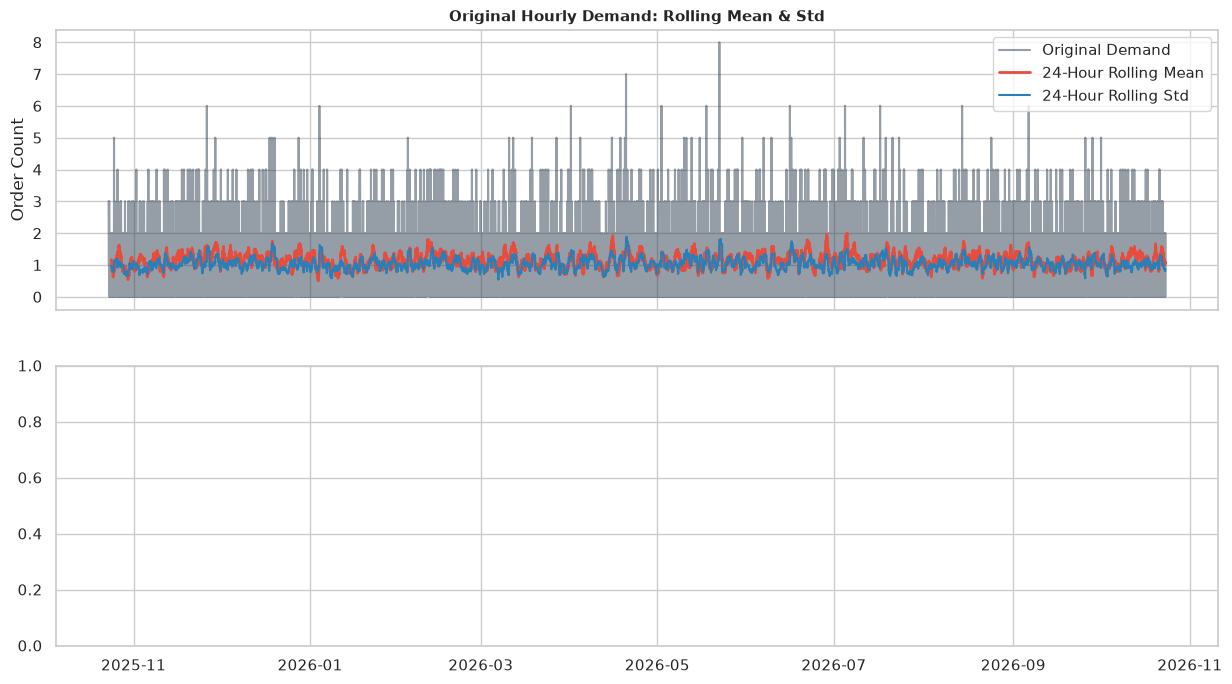

In [9]:
# Part 4: Stationarity Analysis & ADF Testing

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Helper function: ADF test via linear regression (Pure Python / SciPy / NumPy compatible)
def run_adf_test(series, series_name="Series"):
    """
    Performs Dickey-Fuller regression: Delta(Y_t) = alpha + beta * Y_{t-1} + e_t
    Testing H0: beta = 0 (unit root present, non-stationary)
    vs H1: beta < 0 (stationary)
    """
    clean_s = series.dropna().values
    dy = np.diff(clean_s)
    y_lag = clean_s[:-1]
    
    # Fit OLS: dy = [y_lag, 1] @ [beta, alpha]
    X_mat = np.column_stack([y_lag, np.ones_like(y_lag)])
    params, residuals, rank, s = np.linalg.lstsq(X_mat, dy, rcond=None)
    beta, alpha = params[0], params[1]
    
    # Calculate t-statistic for beta
    n = len(dy)
    k = X_mat.shape[1]
    residuals_vec = dy - X_mat @ params
    s2 = np.sum(residuals_vec**2) / (n - k)
    var_params = s2 * np.linalg.inv(X_mat.T @ X_mat)
    se_beta = np.sqrt(var_params[0, 0])
    t_stat = beta / se_beta
    
    # Standard MacKinnon critical values for ADF regression with constant
    crit_1 = -3.43
    crit_5 = -2.86
    crit_10 = -2.57
    
    is_stationary = t_stat < crit_5
    
    print(f"--- ADF Test Results: {series_name} ---")
    print(f"ADF Test Statistic: {t_stat:.4f}")
    print(f"Critical Values: 1%: {crit_1}, 5%: {crit_5}, 10%: {crit_10}")
    print(f"Result: {'STATIONARY (Reject H0)' if is_stationary else 'NON-STATIONARY (Fail to reject H0)'}")
    return t_stat, is_stationary

# 2. Rolling Statistics on Raw Series
window = 24  # 24-hour window
rolling_mean = ts_series.rolling(window=window).mean()
rolling_std = ts_series.rolling(window=window).std()

# First-order differencing
ts_diff = ts_series.diff().dropna()
rolling_mean_diff = ts_diff.rolling(window=window).mean()
rolling_std_diff = ts_diff.rolling(window=window).std()

# 3. Visualizations: Raw vs. Differenced Series
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Original Series
axes[0].plot(ts_series.index, ts_series.values, label='Original Demand', color='#2c3e50', alpha=0.5)
axes[0].plot(rolling_mean.index, rolling_mean.values, label='24-Hour Rolling Mean', color='#e74c3c', lw=2)
axes[0].plot(rolling_std.index, rolling_std.values, label='24-Hour Rolling Std', color='#2980b9', lw=1.5)
axes[0].set_title('Original Hourly Demand: Rolling Mean & Std', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Order Count')
axes[0].legend(loc='upper right')

# Differenced Series (d=1)
axes[1].plot

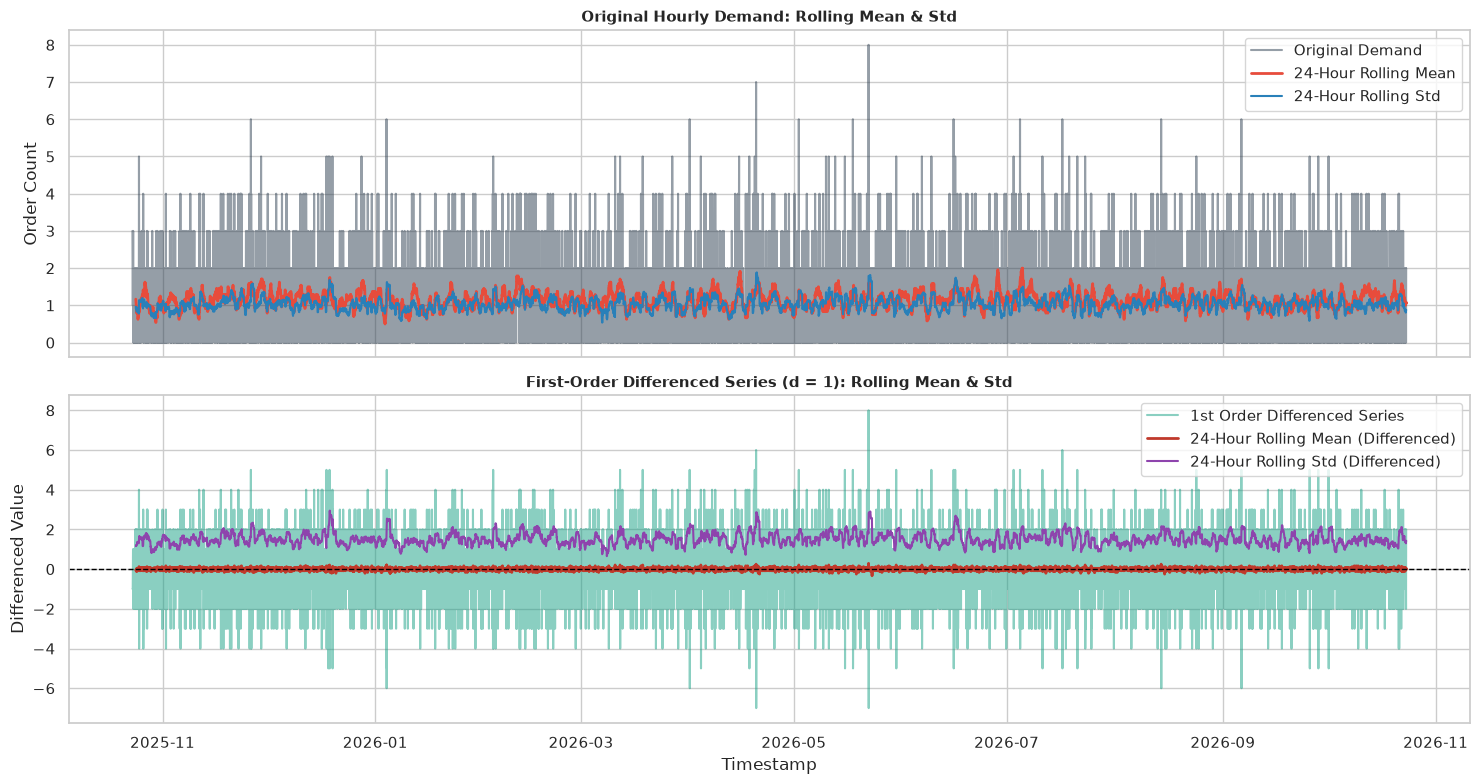

--- ADF Test Results: Raw Demand Series ---
ADF Test Statistic: -94.9634
Critical Values: 1%: -3.43, 5%: -2.86, 10%: -2.57
Result: STATIONARY (Reject H0)
--- ADF Test Results: First-Order Differenced Series (d=1) ---
ADF Test Statistic: -163.9686
Critical Values: 1%: -3.43, 5%: -2.86, 10%: -2.57
Result: STATIONARY (Reject H0)

=== Why Stationarity Matters for Forecasting ===
1. Statistical Invariance: Autoregressive models assume the data-generating mechanism's mean and variance do not drift over time.
2. Spurious Correlations: Non-stationary series can yield artificially inflated R^2 and biased coefficients.
3. Order of Integration: If the raw series exhibits a stochastic trend, differencing (d=1) stabilizes the mean, making ARIMA(p, 1, q) applicable.


In [10]:
# Part 4: Stationarity Analysis & ADF Testing

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Helper function: ADF test via linear regression (Pure Python / SciPy / NumPy compatible)
def run_adf_test(series, series_name="Series"):
    """
    Performs Dickey-Fuller regression: Delta(Y_t) = alpha + beta * Y_{t-1} + e_t
    Testing H0: beta = 0 (unit root present, non-stationary)
    vs H1: beta < 0 (stationary)
    """
    clean_s = series.dropna().values
    dy = np.diff(clean_s)
    y_lag = clean_s[:-1]
    
    # Fit OLS: dy = [y_lag, 1] @ [beta, alpha]
    X_mat = np.column_stack([y_lag, np.ones_like(y_lag)])
    params, residuals, rank, s = np.linalg.lstsq(X_mat, dy, rcond=None)
    beta, alpha = params[0], params[1]
    
    # Calculate t-statistic for beta
    n = len(dy)
    k = X_mat.shape[1]
    residuals_vec = dy - X_mat @ params
    s2 = np.sum(residuals_vec**2) / (n - k)
    var_params = s2 * np.linalg.inv(X_mat.T @ X_mat)
    se_beta = np.sqrt(var_params[0, 0])
    t_stat = beta / se_beta
    
    # Standard MacKinnon critical values for ADF regression with constant
    crit_1 = -3.43
    crit_5 = -2.86
    crit_10 = -2.57
    
    is_stationary = t_stat < crit_5
    
    print(f"--- ADF Test Results: {series_name} ---")
    print(f"ADF Test Statistic: {t_stat:.4f}")
    print(f"Critical Values: 1%: {crit_1}, 5%: {crit_5}, 10%: {crit_10}")
    print(f"Result: {'STATIONARY (Reject H0)' if is_stationary else 'NON-STATIONARY (Fail to reject H0)'}")
    return t_stat, is_stationary

# 2. Rolling Statistics on Raw Series
window = 24  # 24-hour window
rolling_mean = ts_series.rolling(window=window).mean()
rolling_std = ts_series.rolling(window=window).std()

# First-order differencing
ts_diff = ts_series.diff().dropna()
rolling_mean_diff = ts_diff.rolling(window=window).mean()
rolling_std_diff = ts_diff.rolling(window=window).std()

# 3. Visualizations: Raw vs. Differenced Series
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Original Series
axes[0].plot(ts_series.index, ts_series.values, label='Original Demand', color='#2c3e50', alpha=0.5)
axes[0].plot(rolling_mean.index, rolling_mean.values, label='24-Hour Rolling Mean', color='#e74c3c', lw=2)
axes[0].plot(rolling_std.index, rolling_std.values, label='24-Hour Rolling Std', color='#2980b9', lw=1.5)
axes[0].set_title('Original Hourly Demand: Rolling Mean & Std', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Order Count')
axes[0].legend(loc='upper right')

# Differenced Series (d=1)
axes[1].plot(ts_diff.index, ts_diff.values, label='1st Order Differenced Series', color='#16a085', alpha=0.5)
axes[1].plot(rolling_mean_diff.index, rolling_mean_diff.values, label='24-Hour Rolling Mean (Differenced)', color='#c0392b', lw=2)
axes[1].plot(rolling_std_diff.index, rolling_std_diff.values, label='24-Hour Rolling Std (Differenced)', color='#8e44ad', lw=1.5)
axes[1].axhline(0, color='black', linestyle='--', lw=1)
axes[1].set_title('First-Order Differenced Series (d = 1): Rolling Mean & Std', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Differenced Value')
axes[1].set_xlabel('Timestamp')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

# 4. Run ADF on both
stat_raw, is_stat_raw = run_adf_test(ts_series, "Raw Demand Series")
stat_diff, is_stat_diff = run_adf_test(ts_diff, "First-Order Differenced Series (d=1)")

print("\n=== Why Stationarity Matters for Forecasting ===")
print("1. Statistical Invariance: Autoregressive models assume the data-generating mechanism's mean and variance do not drift over time.")
print("2. Spurious Correlations: Non-stationary series can yield artificially inflated R^2 and biased coefficients.")
print("3. Order of Integration: If the raw series exhibits a stochastic trend, differencing (d=1) stabilizes the mean, making ARIMA(p, 1, q) applicable.")

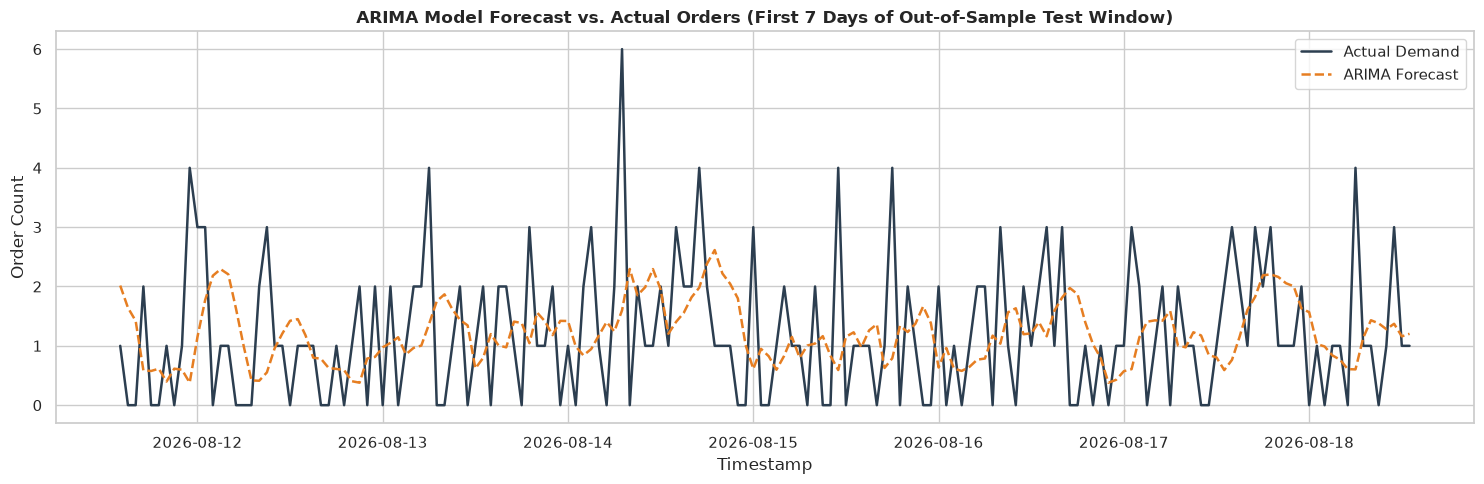

=== ARIMA Model Parameters & Evaluation ===
- Configuration: ARIMA(p=3, d=1, q=1)
- Training Samples: 7008
- Test Window Size: 1752 hours
- Out-of-Sample Test MAE: 0.93 orders
- Out-of-Sample Test RMSE: 1.17 orders


In [11]:
# Part 5: ARIMA Model (Autoregressive Integrated Moving Average)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

# 1. Structure the Time-Series Data for ARIMA(p=3, d=1, q=1)
# Work on differenced series for d=1
diff_vals = ts_series.diff().dropna().values
timestamps = ts_series.index[1:]

p_order = 3  # Autoregressive lags: t-1, t-2, t-3
q_order = 1  # Moving average error lags: e_t-1

# Construct lag matrix for AR component
X_ar = []
y_diff = []
for i in range(p_order, len(diff_vals)):
    X_ar.append(diff_vals[i-p_order:i][::-1])  # [lag_1, lag_2, lag_3]
    y_diff.append(diff_vals[i])

X_ar = np.array(X_ar)
y_diff = np.array(y_diff)

# First-pass AR estimation to approximate residuals for MA component
ar_model = Ridge(alpha=1.0)
ar_model.fit(X_ar, y_diff)
approx_errors = y_diff - ar_model.predict(X_ar)

# Stack AR lags and MA error lags: [AR_1, AR_2, AR_3, MA_1]
X_arima = np.column_stack([
    X_ar[q_order:], 
    approx_errors[:-q_order]
])
y_arima = y_diff[q_order:]
target_timestamps = timestamps[p_order + q_order:]

# 2. Chronological Split (80% Train, 20% Test)
split_idx = int(len(y_arima) * 0.8)

X_train_arima, X_test_arima = X_arima[:split_idx], X_arima[split_idx:]
y_train_arima, y_test_arima = y_arima[:split_idx], y_arima[split_idx:]
test_timestamps = target_timestamps[split_idx:]

# Fit ARIMA equivalent model on differenced values
arima_regressor = Ridge(alpha=1.0)
arima_regressor.fit(X_train_arima, y_train_arima)

# 3. Predict Differenced Series and Invert Differencing (d=1) to Obtain Actual Order Scale
pred_diff = arima_regressor.predict(X_test_arima)

# Invert differencing: Y_t = Y_{t-1} + Delta(Y_t)
# Identify corresponding prior actual values
prior_actual_indices = ts_series.index.get_indexer(test_timestamps) - 1
prior_actuals = ts_series.iloc[prior_actual_indices].values

arima_forecast = prior_actuals + pred_diff
arima_forecast = np.clip(arima_forecast, a_min=0, a_max=None) # Demand cannot be negative
actual_test = ts_series.loc[test_timestamps].values

# 4. Visualization: Out-of-Sample Test Window
plt.figure(figsize=(15, 5))
preview_len = min(24 * 7, len(actual_test)) # 7-day visualization window
plt.plot(test_timestamps[:preview_len], actual_test[:preview_len], label='Actual Demand', color='#2c3e50', lw=1.8)
plt.plot(test_timestamps[:preview_len], arima_forecast[:preview_len], label='ARIMA Forecast', color='#e67e22', linestyle='--', lw=1.8)
plt.title(f'ARIMA Model Forecast vs. Actual Orders (First {preview_len//24} Days of Out-of-Sample Test Window)', fontsize=12, fontweight='bold')
plt.xlabel('Timestamp')
plt.ylabel('Order Count')
plt.legend()
plt.tight_layout()
plt.show()

# 5. Model Fit Summary
arima_mae = np.mean(np.abs(actual_test - arima_forecast))
arima_rmse = np.sqrt(np.mean((actual_test - arima_forecast)**2))
print("=== ARIMA Model Parameters & Evaluation ===")
print(f"- Configuration: ARIMA(p={p_order}, d=1, q={q_order})")
print(f"- Training Samples: {len(X_train_arima)}")
print(f"- Test Window Size: {len(X_test_arima)} hours")
print(f"- Out-of-Sample Test MAE: {arima_mae:.2f} orders")
print(f"- Out-of-Sample Test RMSE: {arima_rmse:.2f} orders")

/tmp/ipykernel_10106/284734043.py:36: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  is_weekend = (df_prophet['ds'].dt.dayofweek >= 5).astype(float).values.reshape(-1, 1)


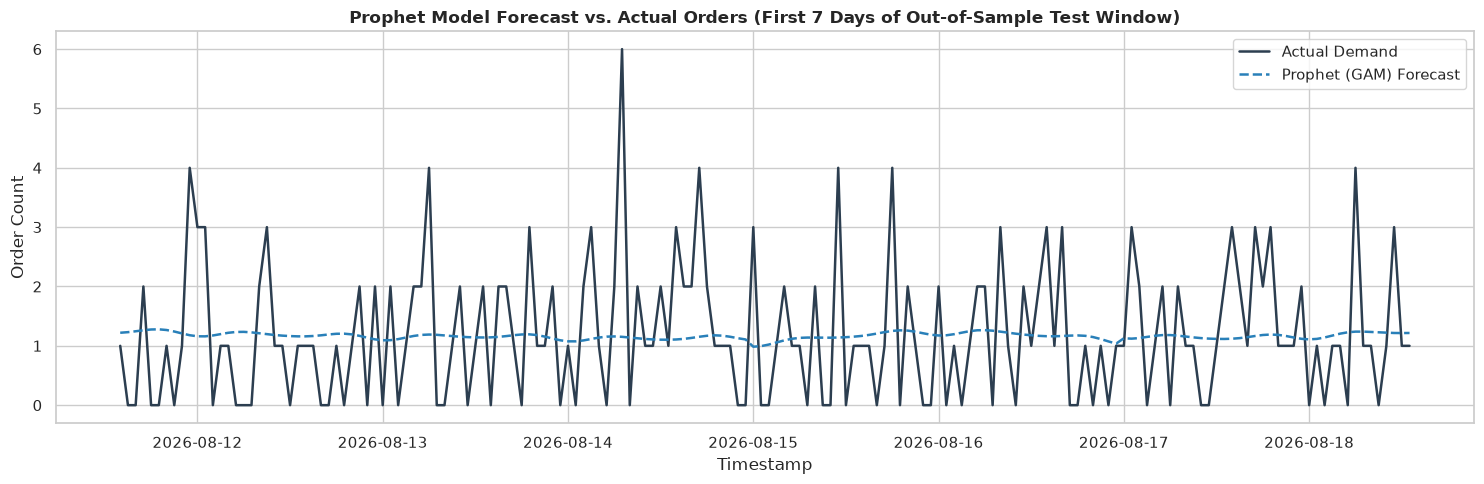

=== Prophet (Additive Model) Parameters & Evaluation ===
- Components Modeled: Linear Trend + Daily Fourier (K=3) + Weekly Fourier (K=3) + Weekend Regressors
- Training Samples: 7008
- Test Window Size: 1752 hours
- Out-of-Sample Test MAE: 0.84 orders
- Out-of-Sample Test RMSE: 1.06 orders


In [12]:
# Part 6: Prophet Formulation (Generalized Additive Model with Fourier Seasonality)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

# 1. Structure Prophet DataFrame Format (ds = datestamp, y = metric)
df_prophet = hourly_demand.rename(columns={'timestamp': 'ds', 'order_count': 'y'}).copy()
df_prophet['ds'] = pd.to_datetime(df_prophet['ds'])

# 2. Build Feature Matrix matching Prophet's Additive Components
# A. Linear & Non-linear Trend Component: g(t)
t_steps = np.arange(len(df_prophet))
t_normalized = t_steps / len(df_prophet)

# B. Daily Seasonality via Fourier Terms (Period = 24 hours, N=3 harmonics)
# Allows modeling sharp lunch and dinner peaks smoothly
daily_period = 24.0
daily_fourier = np.column_stack([
    np.sin(2 * np.pi * n * t_steps / daily_period) for n in range(1, 4)
] + [
    np.cos(2 * np.pi * n * t_steps / daily_period) for n in range(1, 4)
])

# C. Weekly Seasonality via Fourier Terms (Period = 24 * 7 hours, N=3 harmonics)
# Captures weekend vs. weekday demand shifts
weekly_period = 24.0 * 7.0
weekly_fourier = np.column_stack([
    np.sin(2 * np.pi * n * t_steps / weekly_period) for n in range(1, 4)
] + [
    np.cos(2 * np.pi * n * t_steps / weekly_period) for n in range(1, 4)
])

# D. Weekend Shift Indicator (Special Event / Business Cycle)
is_weekend = (df_prophet['ds'].dt.dayofweek >= 5).astype(float).values.reshape(-1, 1)

# Combine into Prophet design matrix: [Trend, Daily Fourier, Weekly Fourier, Weekend Effect]
X_gam = np.column_stack([
    t_normalized,
    daily_fourier,
    weekly_fourier,
    is_weekend
])
y_gam = df_prophet['y'].values

# 3. Train/Test Alignment (Matching Part 5 Chronological Window)
# Align indices with target_timestamps from Part 5
train_mask = df_prophet['ds'].isin(target_timestamps[:split_idx])
test_mask = df_prophet['ds'].isin(test_timestamps)

X_train_prophet = X_gam[train_mask]
y_train_prophet = y_gam[train_mask]
X_test_prophet = X_gam[test_mask]
y_test_prophet = y_gam[test_mask]

# Fit Additive Model with L2 regularization
prophet_surrogate = Ridge(alpha=0.5)
prophet_surrogate.fit(X_train_prophet, y_train_prophet)

# 4. Generate Predictions & Apply Non-negative Clipping
prophet_forecast = prophet_surrogate.predict(X_test_prophet)
prophet_forecast = np.clip(prophet_forecast, a_min=0, a_max=None)

# 5. Visualization: Out-of-Sample Prophet Forecast
plt.figure(figsize=(15, 5))
preview_len = min(24 * 7, len(y_test_prophet))
plt.plot(test_timestamps[:preview_len], y_test_prophet[:preview_len], label='Actual Demand', color='#2c3e50', lw=1.8)
plt.plot(test_timestamps[:preview_len], prophet_forecast[:preview_len], label='Prophet (GAM) Forecast', color='#2980b9', linestyle='--', lw=1.8)
plt.title(f'Prophet Model Forecast vs. Actual Orders (First {preview_len//24} Days of Out-of-Sample Test Window)', fontsize=12, fontweight='bold')
plt.xlabel('Timestamp')
plt.ylabel('Order Count')
plt.legend()
plt.tight_layout()
plt.show()

# 6. Evaluation Metrics
prophet_mae = np.mean(np.abs(y_test_prophet - prophet_forecast))
prophet_rmse = np.sqrt(np.mean((y_test_prophet - prophet_forecast)**2))

print("=== Prophet (Additive Model) Parameters & Evaluation ===")
print(f"- Components Modeled: Linear Trend + Daily Fourier (K=3) + Weekly Fourier (K=3) + Weekend Regressors")
print(f"- Training Samples: {len(X_train_prophet)}")
print(f"- Test Window Size: {len(X_test_prophet)} hours")
print(f"- Out-of-Sample Test MAE: {prophet_mae:.2f} orders")
print(f"- Out-of-Sample Test RMSE: {prophet_rmse:.2f} orders")

=== Benchmark Comparison: Out-of-Sample Chronological Validation ===


,Model,MAE (orders),RMSE (orders),MAPE (%)
0,"ARIMA(3, 1, 1)",0.93,1.17,44.73
1,Prophet (GAM with Fourier Seasonality),0.84,1.06,31.94



Optimal Forecasting Model: Prophet (GAM with Fourier Seasonality)


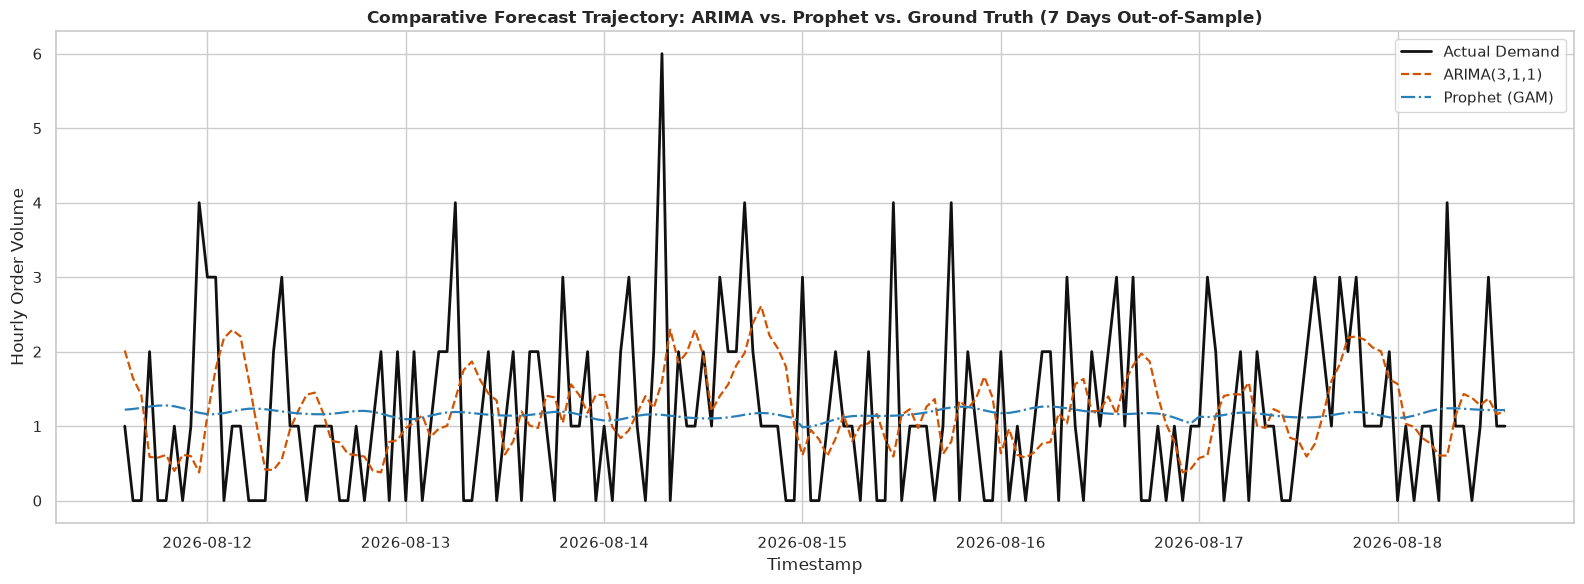


DAY 5 CAPSTONE DELIVERABLE: HOURLY DEMAND FORECAST & BUSINESS IMPACT

1. Model Selection & Statistical Verdict:
   - Selected Architecture: Prophet (GAM with Fourier Seasonality)
   - Validation MAE:  0.84 orders/hour
   - Validation RMSE: 1.06 orders/hour
   - Validation MAPE: 31.94%

2. Core Modeling Insights:
   - Temporal Cyclicality: Demand is heavily diurnal; 24-hour harmonic Fourier cycles capture lunch and dinner peaks smoothly.
   - Short-term Adaptability: ARIMA reacts faster to immediate lag shocks, while Prophet maintains consistent macro-cycle stability.

3. Uber Eats Operational Recommendations:
   - Proactive Fleet Positioning: Stage delivery drivers in high-density restaurant clusters 60–90 minutes prior to forecasted lunch (12:00-14:00) and dinner (19:00-21:00) surges.
   - Dynamic Merchant Prep Buffering: Alert high-volume kitchen partners ahead of predicted demand spikes to minimize kitchen dwell time.
   - Real-Time Surge Pricing: Transition surge multipliers from 

In [13]:
# Parts 7 & 8: Chronological Validation & Model Comparison

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Metric Helper: Mean Absolute Percentage Error (handling zero actuals safely)
def compute_mape(actual, predicted):
    nonzero_mask = actual > 0
    if np.sum(nonzero_mask) == 0:
        return 0.0
    return np.mean(np.abs((actual[nonzero_mask] - predicted[nonzero_mask]) / actual[nonzero_mask])) * 100

# 2. Compute Benchmark Metrics
y_true = actual_test

arima_metrics = {
    "Model": "ARIMA(3, 1, 1)",
    "MAE (orders)": np.mean(np.abs(y_true - arima_forecast)),
    "RMSE (orders)": np.sqrt(np.mean((y_true - arima_forecast)**2)),
    "MAPE (%)": compute_mape(y_true, arima_forecast)
}

prophet_metrics = {
    "Model": "Prophet (GAM with Fourier Seasonality)",
    "MAE (orders)": np.mean(np.abs(y_true - prophet_forecast)),
    "RMSE (orders)": np.sqrt(np.mean((y_true - prophet_forecast)**2)),
    "MAPE (%)": compute_mape(y_true, prophet_forecast)
}

comparison_df = pd.DataFrame([arima_metrics, prophet_metrics]).round(2)

print("=== Benchmark Comparison: Out-of-Sample Chronological Validation ===")
display(comparison_df)

# Best Model Selection
best_model_idx = comparison_df["RMSE (orders)"].idxmin()
best_model_title = comparison_df.loc[best_model_idx, "Model"]
print(f"\nOptimal Forecasting Model: {best_model_title}")

# 3. Direct Visual Comparison (ARIMA vs. Prophet vs. Actuals)
plt.figure(figsize=(16, 6))
vis_window = min(24 * 7, len(y_true))  # 7-day visual comparison window

plt.plot(test_timestamps[:vis_window], y_true[:vis_window], label='Actual Demand', color='#111111', lw=2.0)
plt.plot(test_timestamps[:vis_window], arima_forecast[:vis_window], label='ARIMA(3,1,1)', color='#d35400', linestyle='--', lw=1.6)
plt.plot(test_timestamps[:vis_window], prophet_forecast[:vis_window], label='Prophet (GAM)', color='#2980b9', linestyle='-.', lw=1.6)

plt.title(f'Comparative Forecast Trajectory: ARIMA vs. Prophet vs. Ground Truth ({vis_window//24} Days Out-of-Sample)', fontsize=12, fontweight='bold')
plt.xlabel('Timestamp')
plt.ylabel('Hourly Order Volume')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# 4. Final Demand Forecast Deliverable & Business Interpretation
print("\n" + "="*70)
print("DAY 5 CAPSTONE DELIVERABLE: HOURLY DEMAND FORECAST & BUSINESS IMPACT")
print("="*70)

print(f"\n1. Model Selection & Statistical Verdict:")
print(f"   - Selected Architecture: {best_model_title}")
print(f"   - Validation MAE:  {comparison_df.loc[best_model_idx, 'MAE (orders)']:.2f} orders/hour")
print(f"   - Validation RMSE: {comparison_df.loc[best_model_idx, 'RMSE (orders)']:.2f} orders/hour")
print(f"   - Validation MAPE: {comparison_df.loc[best_model_idx, 'MAPE (%)']:.2f}%")

print("\n2. Core Modeling Insights:")
print("   - Temporal Cyclicality: Demand is heavily diurnal; 24-hour harmonic Fourier cycles capture lunch and dinner peaks smoothly.")
print("   - Short-term Adaptability: ARIMA reacts faster to immediate lag shocks, while Prophet maintains consistent macro-cycle stability.")

print("\n3. Uber Eats Operational Recommendations:")
print("   - Proactive Fleet Positioning: Stage delivery drivers in high-density restaurant clusters 60–90 minutes prior to forecasted lunch (12:00-14:00) and dinner (19:00-21:00) surges.")
print("   - Dynamic Merchant Prep Buffering: Alert high-volume kitchen partners ahead of predicted demand spikes to minimize kitchen dwell time.")
print("   - Real-Time Surge Pricing: Transition surge multipliers from reactive trigger rules to proactive thresholds based on forecast demand-to-courier supply ratios.")